In [ ]:
import jax.numpy as jnp
import blackjax
import ripplegw
import matplotlib.pyplot as plt

/Users/benedictbinu/Documents/Cambridge/Year_4/Research/trial1/.venv/lib/python3.15/site-packages/matplotlib/cbook.py:1811: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/benedictbinu/Documents/Cambridge/Year_4/Research/trial1/.venv/lib/python3.15/site-packages/matplotlib/cbook.py:1408: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


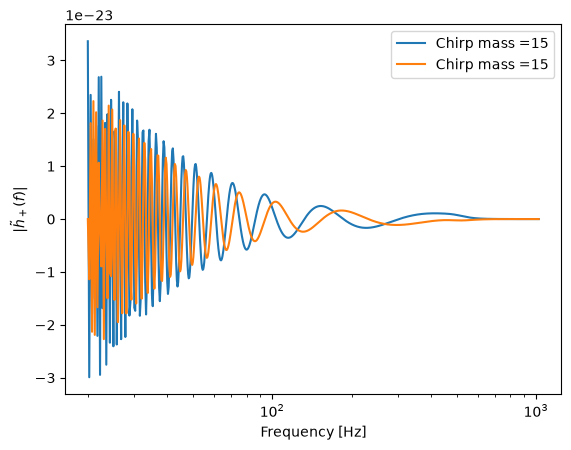

In [ ]:
frequency = jnp.arange(20.0, 1024.0, 0.25)

# GW150914-like binary black hole parameters
mass_values = [15]

for i in mass_values:
    params = {
    "M_c": i,   # chirp mass [solar masses]
    "eta": 0.247,  # symmetric mass ratio
    "s1_z": 0.0,   # primary aligned spin
    "s2_z": 0.0,   # secondary aligned spin
    "d_L": 400,  # luminosity distance [Mpc]
    "phase_c": 0.0,
    "iota": jnp.pi/3,
    }

    # Construct the waveform model by its registered name
    waveform = ripplegw.waveform("IMRPhenomD", f_ref=20)

    # Evaluate: returns a dict with keys "p" (h_+) and "c" (h_x)
    polarizations = waveform(frequency, params)


    hp = polarizations["p"]
    hc = polarizations["c"]

    plt.semilogx(frequency, hp, label = f"Chirp mass ={i}")
    plt.semilogx(frequency, hc, label = f"Chirp mass ={i}") 


plt.legend()
plt.xlabel("Frequency [Hz]")
plt.ylabel(r"$|\tilde h_+(f)|$")
plt.show()


In [13]:
ripplegw.get_waveform_metadata("IMRPhenomD")

{'domain': 'FD',
 'is_tidal': False,
 'is_precessing': False,
 'highest_mode': 2,
 'source_type': 'cbc'}

### Now trying to make 2 overlapping waveforms then work out parameters

In [70]:
#generate overlapping waveforms
frequencies = jnp.arange(20.0, 1024.0, 0.25)

mass_values = [15, 30]

hp_s = []

for mass in mass_values:
    params = {
        "M_c": mass,   # chirp mass [solar masses]
        "eta": 0.247,  # symmetric mass ratio
        "s1_z": 0.0,   # primary aligned spin
        "s2_z": 0.0,   # secondary aligned spin
        "d_L": 400,  # luminosity distance [Mpc]
        "phase_c": 0.0,
        "iota": 0,
    }

    waveform = ripplegw.waveform('IMRPhenomD', f_ref =20)
    polarizations = waveform(frequencies, params)

    hp = polarizations["p"]
    hc = polarizations["c"]
    hp_s.append(hp)

observed = jnp.sum(jnp.stack(hp_s), axis =0) # Summed waveform


In [ ]:
## Now given overall waveform, learn the parameters that created it. 

# first make a log density function, which takes your observed function and tests it out for a certain value of loc --> not sure how to do
def logdensity_fn(loc, log_scale, observed = observed):
    




(2, 4016)